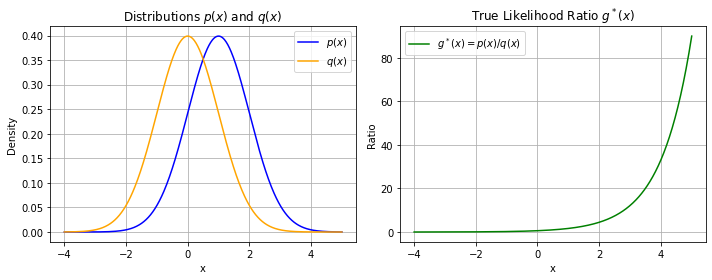

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Step 1: Define true distributions
mu_p, mu_q, sigma = 1.0, 0.0, 1.0
p = lambda x: norm.pdf(x, loc=mu_p, scale=sigma)
q = lambda x: norm.pdf(x, loc=mu_q, scale=sigma)
g_true = lambda x: p(x) / q(x)

# Generate synthetic training samples
n_p, n_q = 300, 300
X_p = np.random.normal(mu_p, sigma, size=n_p)
X_q = np.random.normal(mu_q, sigma, size=n_q)

# Evaluate densities and ratio for plotting
x_grid = np.linspace(-4, 5, 500)
p_vals = p(x_grid)
q_vals = q(x_grid)
g_vals = g_true(x_grid)

# Plot p(x), q(x)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(x_grid, p_vals, label='$p(x)$', color='blue')
plt.plot(x_grid, q_vals, label='$q(x)$', color='orange')
plt.title('Distributions $p(x)$ and $q(x)$')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)

# Plot true ratio g*(x)
plt.subplot(1, 2, 2)
plt.plot(x_grid, g_vals, label='$g^*(x) = p(x)/q(x)$', color='green')
plt.title('True Likelihood Ratio $g^*(x)$')
plt.xlabel('x')
plt.ylabel('Ratio')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [2]:
from sklearn.metrics.pairwise import rbf_kernel

# Step 2: RKHS setup
def compute_kernel_matrices(X_p, X_q, sigma):
    """Compute K_PP and K_QP using RBF kernel."""
    gamma = 1.0 / (2 * sigma ** 2)
    K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    return K_PP, K_QP

# Loss function for optimization
def rkhs_loss(alpha, K_PP, K_QP, lambda_reg):
    """
    Compute the variational loss:
    L(α) = E_Q[ĝ] - E_P[log ĝ] + (λ/2) * αᵀ K_PP α
    where ĝ(x) = K(x, X_p) @ α
    """
    n_p = K_PP.shape[0]
    n_q = K_QP.shape[0]
    g_q = K_QP @ alpha
    g_p = K_PP @ alpha
    g_p = np.clip(g_p, 1e-8, None)

    term_q = np.mean(g_q)
    term_p = -np.mean(np.log(g_p))
    reg = 0.5 * lambda_reg * (alpha @ K_PP @ alpha)

    loss = term_q + term_p + reg
    return loss

# Also compute gradient (optional for optimizers like L-BFGS-B)
def rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg):
    n_p = K_PP.shape[0]
    n_q = K_QP.shape[0]
    g_p = K_PP @ alpha
    g_p = np.clip(g_p, 1e-8, None)

    grad_term_q = np.mean(K_QP, axis=0)
    grad_term_p = -(K_PP @ (1.0 / g_p)) / n_p
    grad_reg = lambda_reg * (K_PP @ alpha)

    grad = grad_term_q + grad_term_p + grad_reg
    return grad

# Example kernel computation
sigma = 1.0
K_PP, K_QP = compute_kernel_matrices(X_p, X_q, sigma)
alpha0 = np.ones(X_p.shape[0]) / X_p.shape[0]

# Show example loss value
lambda_reg = 1e-2
example_loss = rkhs_loss(alpha0, K_PP, K_QP, lambda_reg)
example_grad = rkhs_loss_grad(alpha0, K_PP, K_QP, lambda_reg)

example_loss, example_grad[:5]  # show loss and first 5 gradient entries


(1.0659466959922732,
 array([-0.51317732, -0.46163631, -0.53765898, -0.68881495, -0.67976904]))

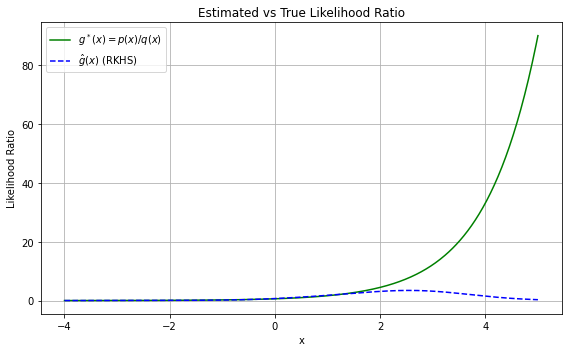

In [3]:
from scipy.optimize import minimize

# Step 3: Solve for optimal alpha
def fit_rkhs_estimator(X_p, X_q, sigma=1.0, lambda_reg=1e-2):
    K_PP, K_QP = compute_kernel_matrices(X_p, X_q, sigma)
    n_p = X_p.shape[0]
    alpha0 = np.ones(n_p) / n_p
    bounds = [(0, None)] * n_p  # alpha_i ≥ 0 for all i

    result = minimize(
        fun=lambda alpha: rkhs_loss(alpha, K_PP, K_QP, lambda_reg),
        x0=alpha0,
        jac=lambda alpha: rkhs_loss_grad(alpha, K_PP, K_QP, lambda_reg),
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': 1000, 'ftol': 1e-9}
    )

    if not result.success:
        raise RuntimeError("Optimization failed: " + result.message)

    return result.x, K_PP

# Fit the estimator
alpha_opt, K_PP = fit_rkhs_estimator(X_p, X_q, sigma=1.0, lambda_reg=1e-2)

# Evaluate the estimated ĝ(x) on a grid
def predict_g_hat(x_vals, X_p, alpha, sigma):
    gamma = 1.0 / (2 * sigma ** 2)
    K_xp = rbf_kernel(x_vals[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
    return K_xp @ alpha

# Plot estimated vs true g(x)
x_grid = np.linspace(-4, 5, 500)
g_hat_vals = predict_g_hat(x_grid, X_p, alpha_opt, sigma)
g_true_vals = g_true(x_grid)

plt.figure(figsize=(8, 5))
plt.plot(x_grid, g_true_vals, label='$g^*(x) = p(x)/q(x)$', color='green')
plt.plot(x_grid, g_hat_vals, label='$\hat{g}(x)$ (RKHS)', linestyle='--', color='blue')
plt.xlabel("x")
plt.ylabel("Likelihood Ratio")
plt.title("Estimated vs True Likelihood Ratio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()